# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [141]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset Iris
iris = load_iris(as_frame=True)
df = iris.frame
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [143]:
print(iris.target_names)
df['target'].value_counts()

['setosa' 'versicolor' 'virginica']


,count
target,
0,50
1,50
2,50


# Identificacion de caracteristicas
1. Cada instancia o fila del dataset representa las características de una flor.

2. En este dataset hay un total de 150 instancias y 4 características.
3. Las características y sus significados son:
  - sepal length (cm): Longitud del sépalo.
  - sepal width (cm): Ancho del sépalo.
  - petal length (cm): Longitud del pétalo
  - petal width (cm): Ancho del pétalo

4. Hay cuatro clases: setosa, versicolor y virginica; cada una con 50 instancias cada una.

In [144]:
print(iris.data.shape)
print(iris.target.shape)

(150, 4)
(150,)


5. Las dimensiones de la matriz de caracteristicas es de 150x4, mientras que el vector de caracteristicas es de solo 150

In [145]:
df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


/tmp/ipykernel_2221/3813651147.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['target'].map(dict(enumerate(iris.target_names))), palette='viridis')


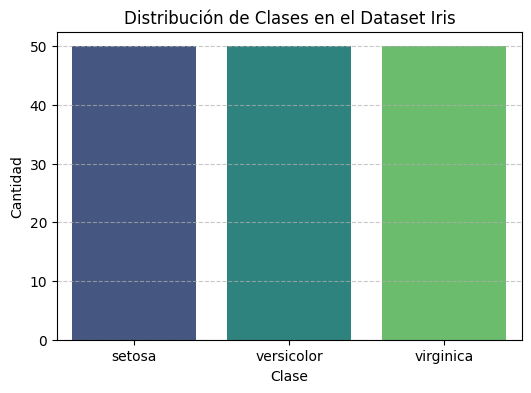

In [146]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df['target'].map(dict(enumerate(iris.target_names))), palette='viridis')
plt.title('Distribución de Clases en el Dataset Iris')
plt.xlabel('Clase')
plt.ylabel('Cantidad')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

#Predicciones inciales
1. Yo pienso que los SVMs y la regresión logistica seran los mas afectados ya que se basan en mediciones de distancias.
2. El que puede generar fronteras de desiciones mas simples es el Naive Bayes ya que hace probabilidades simples.
3. No podemos asegurar cual puede ser mejor de antemano ya que cada uno se comporta de manera diferente tomando en cuenta la cantidad de los datos y la varianza que pueden llegar a tener.

In [147]:
from sklearn.model_selection import train_test_split

X= df.drop('target', axis=1)
y= df['target']

# Train test split
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
# Validacion
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

resultados = []

In [148]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [149]:
# Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)


GaussianNB()

In [150]:
# Prediccion
y_pred_gnb = gnb.predict(X_val_scaled)

# Métricas
print("--- Gaussian Naive Bayes ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_gnb):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_gnb, average='macro'):.4f}")

--- Gaussian Naive Bayes ---
Accuracy: 0.9333
F1 macro: 0.9333


In [151]:
mejor_f1, mejor_acc, mejor_vs = -1, -1, None
for vs in [1e-9, 1e-6, 1e-3, 1e-1]:
    m = GaussianNB(var_smoothing=vs)
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_val_scaled)
    acc = accuracy_score(y_val, p)
    f1 = f1_score(y_val, p, average="macro")
    print(f"var_smoothing={vs}  acc={acc:.3f}  f1={f1:.3f}")
    if (f1, acc) > (mejor_f1, mejor_acc):
        mejor_f1, mejor_acc, mejor_vs = f1, acc, vs
print("Mejor var_smoothing:", mejor_vs)

# Configuración congelada y evaluación en prueba
gnb_final = GaussianNB(var_smoothing=mejor_vs)
gnb_final.fit(X_train_scaled, y_train)
y_pred_test_gnb = gnb_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "Gaussian NB",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"var_smoothing={mejor_vs}",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_gnb),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_gnb, average="macro"),
})

var_smoothing=1e-09  acc=0.933  f1=0.933
var_smoothing=1e-06  acc=0.933  f1=0.933
var_smoothing=0.001  acc=0.933  f1=0.933
var_smoothing=0.1  acc=0.900  f1=0.900
Mejor var_smoothing: 1e-09


In [152]:
# Regresión logistica
lr = LogisticRegression(max_iter=200, random_state=42)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=200, random_state=42)

In [153]:
# 2. Predecir en validación
y_pred_lr = lr.predict(X_val_scaled)

# 3. Métricas
print("--- Regresión Logística ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_lr):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_lr, average='macro'):.4f}")

--- Regresión Logística ---
Accuracy: 0.9333
F1 macro: 0.9333


In [154]:
mejor_f1, mejor_acc, mejor_C = -1, -1, None
for c in [0.01, 0.1, 1, 10, 100]:
    m = LogisticRegression(C=c, max_iter=200, random_state=42)
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_val_scaled)
    acc = accuracy_score(y_val, p)
    f1 = f1_score(y_val, p, average="macro")
    print(f"C={c}  acc={acc:.3f}  f1={f1:.3f}")
    if (f1, acc) > (mejor_f1, mejor_acc):
        mejor_f1, mejor_acc, mejor_C = f1, acc, c
print("Mejor C:", mejor_C)

# --- Configuración congelada y evaluación en prueba ---
lr_final = LogisticRegression(C=mejor_C, max_iter=200, random_state=42)
lr_final.fit(X_train_scaled, y_train)
y_pred_test_lr = lr_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "Regresión logística",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"C={mejor_C}, max_iter=200",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_lr),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_lr, average="macro"),
})

C=0.01  acc=0.800  f1=0.792
C=0.1  acc=0.867  f1=0.865
C=1  acc=0.933  f1=0.933
C=10  acc=0.933  f1=0.933
C=100  acc=0.933  f1=0.933
Mejor C: 1


In [155]:
# SVM lineal
# 1. Instanciar y entrenar
svm_lineal = SVC(kernel='linear', random_state=42)
svm_lineal.fit(X_train_scaled, y_train)

SVC(kernel='linear', random_state=42)

In [156]:
# 2. Predecir en validación
y_pred_svm = svm_lineal.predict(X_val_scaled)

# 3. Métricas
print("--- SVM Lineal ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_svm):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_svm, average='macro'):.4f}")

--- SVM Lineal ---
Accuracy: 0.9333
F1 macro: 0.9333


In [157]:
mejor_f1, mejor_acc, mejor_C = -1, -1, None
for c in [0.01, 0.1, 1, 10]:
    m = SVC(kernel="linear", C=c, random_state=42)
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_val_scaled)
    acc = accuracy_score(y_val, p)
    f1 = f1_score(y_val, p, average="macro")
    print(f"C={c}  acc={acc:.3f}  f1={f1:.3f}")
    if (f1, acc) > (mejor_f1, mejor_acc):
        mejor_f1, mejor_acc, mejor_C = f1, acc, c
print("Mejor C:", mejor_C)

# --- Configuración congelada y evaluación en prueba ---
svm_final = SVC(kernel="linear", C=mejor_C, random_state=42)
svm_final.fit(X_train_scaled, y_train)
y_pred_test_svm = svm_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "SVM lineal",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"kernel=linear, C={mejor_C}",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_svm),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_svm, average="macro"),
})

C=0.01  acc=0.833  f1=0.833
C=0.1  acc=0.933  f1=0.933
C=1  acc=0.933  f1=0.933
C=10  acc=0.900  f1=0.900
Mejor C: 0.1


In [158]:
# Arbol de decision
# 1. Instanciar y entrenar
arbol = DecisionTreeClassifier(random_state=42)
arbol.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [159]:
# 2. Predecir en validación
y_pred_arbol = arbol.predict(X_val_scaled)

# 3. Métricas
print("--- Árbol de Decisión ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_arbol):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_arbol, average='macro'):.4f}")

--- Árbol de Decisión ---
Accuracy: 0.9333
F1 macro: 0.9333


In [160]:
mejor_f1, mejor_acc, mejor_d = -1, -1, "sin_valor"
for d in [1, 2, 3, 4, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_scaled, y_train)
    p = m.predict(X_val_scaled)
    acc = accuracy_score(y_val, p)
    f1 = f1_score(y_val, p, average="macro")
    print(f"max_depth={d}  acc={acc:.3f}  f1={f1:.3f}")
    if (f1, acc) > (mejor_f1, mejor_acc):
        mejor_f1, mejor_acc, mejor_d = f1, acc, d
print("Mejor max_depth:", mejor_d)

# --- Configuración congelada y evaluación en prueba ---
arbol_final = DecisionTreeClassifier(max_depth=mejor_d, random_state=42)
arbol_final.fit(X_train_scaled, y_train)
y_pred_test_arbol = arbol_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "Árbol de decisión",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"max_depth={mejor_d}",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_arbol),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_arbol, average="macro"),
})

max_depth=1  acc=0.667  f1=0.556
max_depth=2  acc=0.900  f1=0.900
max_depth=3  acc=0.900  f1=0.900
max_depth=4  acc=0.933  f1=0.933
max_depth=None  acc=0.933  f1=0.933
Mejor max_depth: 4


In [161]:
# Random Forest
# 1. Instanciar y entrenar
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [162]:
# 2. Predecir en validación
y_pred_rf = rf.predict(X_val_scaled)

# 3. Métricas
print("--- Random Forest ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_rf):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_rf, average='macro'):.4f}")

--- Random Forest ---
Accuracy: 0.9333
F1 macro: 0.9333


In [163]:
mejor_f1, mejor_acc, mejor_n, mejor_d = -1, -1, None, "sin_valor"
for n in [50, 100, 300]:
    for d in [2, 3, None]:
        m = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=42)
        m.fit(X_train_scaled, y_train)
        p = m.predict(X_val_scaled)
        acc = accuracy_score(y_val, p)
        f1 = f1_score(y_val, p, average="macro")
        print(f"n_estimators={n}, max_depth={d}  acc={acc:.3f}  f1={f1:.3f}")
        if (f1, acc) > (mejor_f1, mejor_acc):
            mejor_f1, mejor_acc, mejor_n, mejor_d = f1, acc, n, d
print("Mejor configuración:", mejor_n, mejor_d)

# --- Configuración congelada y evaluación en prueba ---
rf_final = RandomForestClassifier(n_estimators=mejor_n, max_depth=mejor_d, random_state=42)
rf_final.fit(X_train_scaled, y_train)
y_pred_test_rf = rf_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "Random Forest",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"n_estimators={mejor_n}, max_depth={mejor_d}",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_rf),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_rf, average="macro"),
})

n_estimators=50, max_depth=2  acc=0.933  f1=0.933
n_estimators=50, max_depth=3  acc=0.933  f1=0.933
n_estimators=50, max_depth=None  acc=0.933  f1=0.933
n_estimators=100, max_depth=2  acc=0.900  f1=0.900
n_estimators=100, max_depth=3  acc=0.933  f1=0.933
n_estimators=100, max_depth=None  acc=0.933  f1=0.933
n_estimators=300, max_depth=2  acc=0.900  f1=0.900
n_estimators=300, max_depth=3  acc=0.933  f1=0.933
n_estimators=300, max_depth=None  acc=0.933  f1=0.933
Mejor configuración: 50 2


In [164]:
# Gradient Booster
# 1. Instanciar y entrenar
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_scaled, y_train)

GradientBoostingClassifier(random_state=42)

In [165]:
# 2. Predecir en validación
y_pred_gb = gb.predict(X_val_scaled)

# 3. Métricas
print("--- Gradient Boosting ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_gb):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_gb, average='macro'):.4f}")

--- Gradient Boosting ---
Accuracy: 0.9000
F1 macro: 0.8997


In [166]:
mejor_f1, mejor_acc, mejor_n, mejor_lr = -1, -1, None, None
for n in [50, 100]:
    for lr_rate in [0.05, 0.1, 0.3]:
        m = GradientBoostingClassifier(n_estimators=n, learning_rate=lr_rate, random_state=42)
        m.fit(X_train_scaled, y_train)
        p = m.predict(X_val_scaled)
        acc = accuracy_score(y_val, p)
        f1 = f1_score(y_val, p, average="macro")
        print(f"n_estimators={n}, learning_rate={lr_rate}  acc={acc:.3f}  f1={f1:.3f}")
        if (f1, acc) > (mejor_f1, mejor_acc):
            mejor_f1, mejor_acc, mejor_n, mejor_lr = f1, acc, n, lr_rate
print("Mejor configuración:", mejor_n, mejor_lr)

# --- Configuración congelada y evaluación en prueba ---
gb_final = GradientBoostingClassifier(n_estimators=mejor_n, learning_rate=mejor_lr, random_state=42)
gb_final.fit(X_train_scaled, y_train)
y_pred_test_gb = gb_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "Gradient Boosting",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"n_estimators={mejor_n}, learning_rate={mejor_lr}",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_gb),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_gb, average="macro"),
})

n_estimators=50, learning_rate=0.05  acc=0.933  f1=0.933
n_estimators=50, learning_rate=0.1  acc=0.900  f1=0.900
n_estimators=50, learning_rate=0.3  acc=0.900  f1=0.900
n_estimators=100, learning_rate=0.05  acc=0.900  f1=0.900
n_estimators=100, learning_rate=0.1  acc=0.900  f1=0.900
n_estimators=100, learning_rate=0.3  acc=0.900  f1=0.900
Mejor configuración: 50 0.05


In [167]:
# MLP
# 1. Instanciar y entrenar
mlp = MLPClassifier(max_iter=500, random_state=42)
mlp.fit(X_train_scaled, y_train)

MLPClassifier(max_iter=500, random_state=42)

In [168]:
# 2. Predecir en validación
y_pred_mlp = mlp.predict(X_val_scaled)

# 3. Métricas
print("--- MLP de Clasificación ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_mlp):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_mlp, average='macro'):.4f}")

--- MLP de Clasificación ---
Accuracy: 0.9333
F1 macro: 0.9333


In [169]:
mejor_f1, mejor_acc, mejor_h, mejor_a = -1, -1, None, None
for h in [(8,), (16,), (32, 16)]:
    for a in [1e-4, 1e-2, 1]:
        m = MLPClassifier(hidden_layer_sizes=h, alpha=a, max_iter=1000, random_state=42)
        m.fit(X_train_scaled, y_train)
        p = m.predict(X_val_scaled)
        acc = accuracy_score(y_val, p)
        f1 = f1_score(y_val, p, average="macro")
        print(f"hidden_layer_sizes={h}, alpha={a}  acc={acc:.3f}  f1={f1:.3f}")
        if (f1, acc) > (mejor_f1, mejor_acc):
            mejor_f1, mejor_acc, mejor_h, mejor_a = f1, acc, h, a
print("Mejor configuración:", mejor_h, mejor_a)

# --- Configuración congelada y evaluación en prueba ---
mlp_final = MLPClassifier(hidden_layer_sizes=mejor_h, alpha=mejor_a, max_iter=1000, random_state=42)
mlp_final.fit(X_train_scaled, y_train)
y_pred_test_mlp = mlp_final.predict(X_test_scaled)

resultados.append({
    "Modelo": "MLP",
    "Transformación": "StandardScaler",
    "Hiperparámetros principales": f"hidden_layer_sizes={mejor_h}, alpha={mejor_a}, max_iter=1000",
    "Accuracy de prueba": accuracy_score(y_test, y_pred_test_mlp),
    "F1 macro de prueba": f1_score(y_test, y_pred_test_mlp, average="macro"),
})

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


hidden_layer_sizes=(8,), alpha=0.0001  acc=0.900  f1=0.900


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


hidden_layer_sizes=(8,), alpha=0.01  acc=0.900  f1=0.900


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


hidden_layer_sizes=(8,), alpha=1  acc=0.900  f1=0.900
hidden_layer_sizes=(16,), alpha=0.0001  acc=0.933  f1=0.933
hidden_layer_sizes=(16,), alpha=0.01  acc=0.933  f1=0.933
hidden_layer_sizes=(16,), alpha=1  acc=0.933  f1=0.933
hidden_layer_sizes=(32, 16), alpha=0.0001  acc=0.900  f1=0.900
hidden_layer_sizes=(32, 16), alpha=0.01  acc=0.900  f1=0.900
hidden_layer_sizes=(32, 16), alpha=1  acc=0.933  f1=0.933
Mejor configuración: (16,) 0.0001


In [170]:
tabla_test = pd.DataFrame(resultados)
print(len(tabla_test))      # debe ser 7
tabla_test.round(3)

7


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian NB,StandardScaler,var_smoothing=1e-09,0.933,0.933
1,Regresión logística,StandardScaler,"C=1, max_iter=200",0.933,0.933
2,SVM lineal,StandardScaler,"kernel=linear, C=0.1",0.933,0.933
3,Árbol de decisión,StandardScaler,max_depth=4,0.933,0.933
4,Random Forest,StandardScaler,"n_estimators=50, max_depth=2",0.933,0.933
5,Gradient Boosting,StandardScaler,"n_estimators=50, learning_rate=0.05",0.933,0.933
6,MLP,StandardScaler,"hidden_layer_sizes=(16,), alpha=0.0001, max_it...",0.933,0.933


# Matrices de confusión

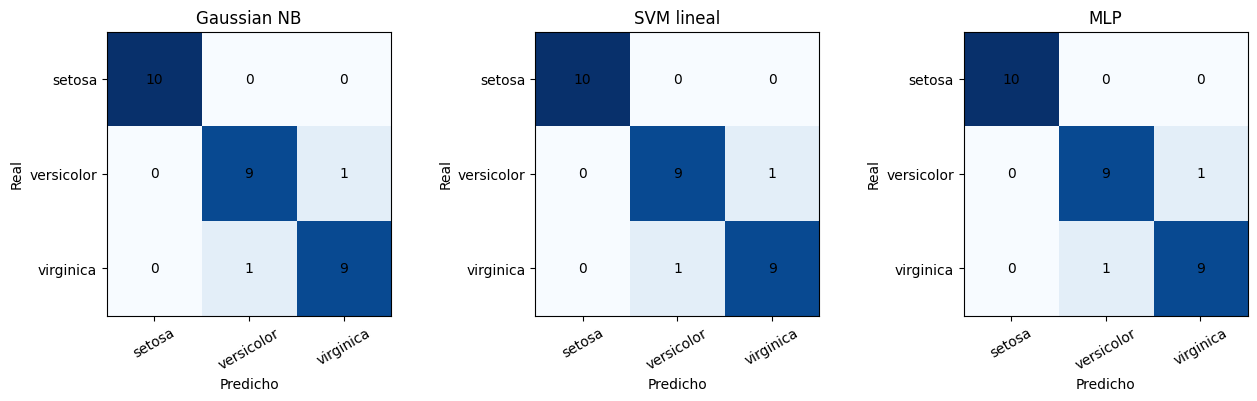

In [171]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, nombre, pred in [(axes[0], "Gaussian NB", y_pred_test_gnb),
                         (axes[1], "SVM lineal", y_pred_test_svm),
                         (axes[2], "MLP", y_pred_test_mlp)]:
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(nombre)
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["setosa", "versicolor", "virginica"], rotation=30)
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["setosa", "versicolor", "virginica"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

# Interpretación de los resultados
1. Todos los modelos tuvieron virtualmente e mismo desempeño al hacer ajustes minimos a los hiperparámetros de cada modelo
2. El modelo de Naive Bayes fue el mas facil de implementar ya que este requiere tomar en cuenta un solo hiperparámetro, a comparación de la implementacion de la red neuronal.
3. Debido a que los datos estaban distribuidos similarmente, ambas metricas con identicas.
4. Las métricas macro se calculan por clase y se promedian con pesos iguales, mientras que las métricas micro hace una sumatoria de los resultados de las matrices de confusion haciendo que los pesos mayores influyan más.
5. Una red neuronal permite la implementación de capas ocultas y otras transformaciones para representar fronteras no lineales.

# Analisis de Errores

In [172]:
## Errores de SVC
mask = y_pred_test_svm != y_test
errores = X_test[mask].copy()
errores["real"] = y_test[mask].values
errores["predicho"] = y_pred_test_svm[mask]
print(errores)

# Medias por clase para comparar (usa tu df original)
print(df.groupby("target")[list(X.columns)].mean())

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
134                6.1               2.6                5.6               1.4   
77                 6.7               3.0                5.0               1.7   

     real  predicho  
134     2         1  
77      1         2  
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
target                                                           
0                   5.006             3.428              1.462   
1                   5.936             2.770              4.260   
2                   6.588             2.974              5.552   

        petal width (cm)  
target                    
0                  0.246  
1                  1.326  
2                  2.026  


En este ejemplo del SVC, los errores corresponden a predicciones erroneas, el error 134 corresponde a una prediccion de versicolor cuando en realidad la flor era de la clase verginica, debido a que las medidas del ancho y largo del cépalo eran mas parecido a la clase 1 que a la clase 2.

Por otro lado en el error 77 ocurre lo contrario, se predice una flor verginica cuando en realidad era versicolor debido a que todas sus medidas son mas cercanas a la clase 2.

Lo que no puedo concluir de la causa de estos errores es si fue por un tema de calculo o si fue por sobreajuste del modelo.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

In [173]:
# Carga de dataset Diabetes
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
df2 = diabetes.frame
df2.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [174]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [175]:
diabetesoriginal= load_diabetes(scaled=False, as_frame=True)
dforiginal = diabetesoriginal.frame
dforiginal.head()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


# Identificacion de caracteristicas
1. El objetivo o target numerico es una cantidad que mide la progresión de la enfermedad en un año.
2. Las variables que contiene el dataset son la edad, el sexo, el indice de masa corporal, presión arterial y la cantidad de lipoproteinas e índices de colesterol de una persona.
3. El dataset ya incluye transformaciones en la data, por lo que todos los datos estan normalizados.

# Prediccion Inicial
Un modelo mas flexible no tendria menos error al encontrarse con datos nuevos, mas bien podria entrar en un sobreajuste ya que un dato nuevo podria ingresar ruido el cual el modelo podria darle mas relevancia y podria llegar a memorizarlo.

In [176]:
SEED = 42

Xd = df2.drop(columns="target")
yd = df2["target"]

# Train test split
Xd_trainval, Xd_test, yd_trainval, yd_test = train_test_split(Xd, yd, test_size=0.20, random_state=SEED)
Xd_train, Xd_val, yd_train, yd_val = train_test_split(Xd_trainval, yd_trainval, test_size=0.25, random_state=SEED)
print("train:", len(yd_train), " val:", len(yd_val), " test:", len(yd_test))

# Escalamiento
y_scaler = StandardScaler()
yd_train_s = y_scaler.fit_transform(yd_train.values.reshape(-1, 1)).ravel()

resultados_reg = []

train: 264  val: 89  test: 89


In [177]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [178]:
# Regresión lineal
lin = Pipeline([("escalador", StandardScaler()), ("modelo", LinearRegression())])
lin.fit(Xd_train, yd_train)

Pipeline(steps=[('escalador', StandardScaler()),
                ('modelo', LinearRegression())])

In [179]:
# Validación
p = lin.predict(Xd_val)
print(f"VAL  MAE={mean_absolute_error(yd_val, p):.2f}  "
      f"RMSE={np.sqrt(mean_squared_error(yd_val, p)):.2f}  R2={r2_score(yd_val, p):.3f}")

VAL  MAE=42.94  RMSE=51.19  R2=0.522


In [180]:
# Prueba
y_pred_test_lin = lin.predict(Xd_test)
resultados_reg.append({
    "Modelo": "Regresión lineal",
    "Hiperparámetros": "-",
    "MAE": mean_absolute_error(yd_test, y_pred_test_lin),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_lin)),
    "R²": r2_score(yd_test, y_pred_test_lin),
})

In [181]:
# Ridge
alphas_ridge = [0.01, 0.1, 1, 10, 100, 1000]

mejor_rmse, mejor_a = np.inf, None
for a in alphas_ridge:
    m = Pipeline([("escalador", StandardScaler()), ("modelo", Ridge(alpha=a))])
    m.fit(Xd_train, yd_train)
    p = m.predict(Xd_val)
    mae = mean_absolute_error(yd_val, p)
    rmse = np.sqrt(mean_squared_error(yd_val, p))
    r2 = r2_score(yd_val, p)
    print(f"alpha={a}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
    if rmse < mejor_rmse:
        mejor_rmse, mejor_a = rmse, a
print("Mejor alpha:", mejor_a)

alpha=0.01  MAE=42.94  RMSE=51.19  R2=0.522
alpha=0.1  MAE=42.91  RMSE=51.17  R2=0.522
alpha=1  MAE=42.72  RMSE=51.10  R2=0.523
alpha=10  MAE=42.62  RMSE=51.16  R2=0.522
alpha=100  MAE=43.43  RMSE=51.74  R2=0.511
alpha=1000  MAE=52.10  RMSE=60.60  R2=0.330
Mejor alpha: 1


In [182]:
# Prueba
ridge_final = Pipeline([("escalador", StandardScaler()), ("modelo", Ridge(alpha=mejor_a))])
ridge_final.fit(Xd_train, yd_train)
y_pred_test_ridge = ridge_final.predict(Xd_test)
resultados_reg.append({
    "Modelo": "Ridge",
    "Hiperparámetros": f"alpha={mejor_a}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_ridge),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_ridge)),
    "R²": r2_score(yd_test, y_pred_test_ridge),
})

In [183]:
# Lasso
alphas_lasso = [0.01, 0.1, 1, 5, 10, 30]

mejor_rmse, mejor_a = np.inf, None
for a in alphas_lasso:
    m = Pipeline([("escalador", StandardScaler()), ("modelo", Lasso(alpha=a, max_iter=10000))])
    m.fit(Xd_train, yd_train)
    p = m.predict(Xd_val)
    mae = mean_absolute_error(yd_val, p)
    rmse = np.sqrt(mean_squared_error(yd_val, p))
    r2 = r2_score(yd_val, p)
    print(f"alpha={a}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
    if rmse < mejor_rmse:
        mejor_rmse, mejor_a = rmse, a
print("Mejor alpha:", mejor_a)

alpha=0.01  MAE=42.91  RMSE=51.18  R2=0.522
alpha=0.1  MAE=42.64  RMSE=51.10  R2=0.523
alpha=1  MAE=42.47  RMSE=51.06  R2=0.524
alpha=5  MAE=43.29  RMSE=51.37  R2=0.518
alpha=10  MAE=45.14  RMSE=53.15  R2=0.484
alpha=30  MAE=55.11  RMSE=63.91  R2=0.255
Mejor alpha: 1


In [184]:
# Prueba
lasso_final = Pipeline([("escalador", StandardScaler()), ("modelo", Lasso(alpha=mejor_a, max_iter=10000))])
lasso_final.fit(Xd_train, yd_train)
y_pred_test_lasso = lasso_final.predict(Xd_test)
resultados_reg.append({
    "Modelo": "Lasso",
    "Hiperparámetros": f"alpha={mejor_a}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_lasso),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_lasso)),
    "R²": r2_score(yd_test, y_pred_test_lasso),
})

In [185]:
# kNN de regresión
mejor_rmse, mejor_k = np.inf, None
for k in [3, 5, 7, 10, 15, 20]:
    m = Pipeline([("escalador", StandardScaler()), ("modelo", KNeighborsRegressor(n_neighbors=k))])
    m.fit(Xd_train, yd_train)
    p = m.predict(Xd_val)
    mae = mean_absolute_error(yd_val, p)
    rmse = np.sqrt(mean_squared_error(yd_val, p))
    r2 = r2_score(yd_val, p)
    print(f"n_neighbors={k}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
    if rmse < mejor_rmse:
        mejor_rmse, mejor_k = rmse, k
print("Mejor n_neighbors:", mejor_k)


n_neighbors=3  MAE=45.92  RMSE=61.60  R2=0.307
n_neighbors=5  MAE=45.29  RMSE=56.83  R2=0.410
n_neighbors=7  MAE=45.48  RMSE=56.79  R2=0.411
n_neighbors=10  MAE=43.86  RMSE=54.64  R2=0.455
n_neighbors=15  MAE=44.21  RMSE=53.65  R2=0.475
n_neighbors=20  MAE=45.56  RMSE=54.55  R2=0.457
Mejor n_neighbors: 15


In [186]:
# Prueba
knn_final = Pipeline([("escalador", StandardScaler()), ("modelo", KNeighborsRegressor(n_neighbors=mejor_k))])
knn_final.fit(Xd_train, yd_train)
y_pred_test_knn = knn_final.predict(Xd_test)
resultados_reg.append({
    "Modelo": "kNN",
    "Hiperparámetros": f"n_neighbors={mejor_k}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_knn),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_knn)),
    "R²": r2_score(yd_test, y_pred_test_knn),
})

In [187]:
# Árbol de regresión
mejor_rmse, mejor_d = np.inf, "sin_valor"
for d in [2, 3, 4, 5, None]:
    m = DecisionTreeRegressor(max_depth=d, random_state=SEED)
    m.fit(Xd_train, yd_train)
    p = m.predict(Xd_val)
    mae = mean_absolute_error(yd_val, p)
    rmse = np.sqrt(mean_squared_error(yd_val, p))
    r2 = r2_score(yd_val, p)
    print(f"max_depth={d}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
    if rmse < mejor_rmse:
        mejor_rmse, mejor_d = rmse, d
print("Mejor max_depth:", mejor_d)

max_depth=2  MAE=46.68  RMSE=58.78  R2=0.369
max_depth=3  MAE=46.57  RMSE=58.23  R2=0.381
max_depth=4  MAE=47.24  RMSE=59.76  R2=0.348
max_depth=5  MAE=47.08  RMSE=59.44  R2=0.355
max_depth=None  MAE=50.37  RMSE=65.81  R2=0.210
Mejor max_depth: 3


In [188]:
# Prueba
arbol_final = DecisionTreeRegressor(max_depth=mejor_d, random_state=SEED)
arbol_final.fit(Xd_train, yd_train)
y_pred_test_arbol = arbol_final.predict(Xd_test)
resultados_reg.append({
    "Modelo": "Árbol de regresión",
    "Hiperparámetros": f"max_depth={mejor_d}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_arbol),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_arbol)),
    "R²": r2_score(yd_test, y_pred_test_arbol),
})

In [189]:
# Random Forest de regresión
mejor_rmse, mejor_n, mejor_d = np.inf, None, "sin_valor"
for n in [100, 300]:
    for d in [3, 5, None]:
        m = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=SEED)
        m.fit(Xd_train, yd_train)
        p = m.predict(Xd_val)
        mae = mean_absolute_error(yd_val, p)
        rmse = np.sqrt(mean_squared_error(yd_val, p))
        r2 = r2_score(yd_val, p)
        print(f"n_estimators={n}, max_depth={d}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
        if rmse < mejor_rmse:
            mejor_rmse, mejor_n, mejor_d = rmse, n, d
print("Mejor configuración:", mejor_n, mejor_d)

n_estimators=100, max_depth=3  MAE=43.39  RMSE=53.81  R2=0.471
n_estimators=100, max_depth=5  MAE=44.17  RMSE=54.70  R2=0.454
n_estimators=100, max_depth=None  MAE=44.64  RMSE=54.29  R2=0.462
n_estimators=300, max_depth=3  MAE=43.39  RMSE=53.95  R2=0.469
n_estimators=300, max_depth=5  MAE=43.79  RMSE=54.24  R2=0.463
n_estimators=300, max_depth=None  MAE=44.55  RMSE=54.32  R2=0.461
Mejor configuración: 100 3


In [190]:
# Prueba
rf_final = RandomForestRegressor(n_estimators=mejor_n, max_depth=mejor_d, random_state=SEED)
rf_final.fit(Xd_train, yd_train)
y_pred_test_rf = rf_final.predict(Xd_test)
resultados_reg.append({
    "Modelo": "Random Forest",
    "Hiperparámetros": f"n_estimators={mejor_n}, max_depth={mejor_d}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_rf),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_rf)),
    "R²": r2_score(yd_test, y_pred_test_rf),
})

In [191]:
# Gradient Boosting de regresión
mejor_rmse, mejor_n, mejor_lr = np.inf, None, None
for n in [50, 100, 200]:
    for lr_rate in [0.01, 0.05, 0.1]:
        m = GradientBoostingRegressor(n_estimators=n, learning_rate=lr_rate, random_state=SEED)
        m.fit(Xd_train, yd_train)
        p = m.predict(Xd_val)
        mae = mean_absolute_error(yd_val, p)
        rmse = np.sqrt(mean_squared_error(yd_val, p))
        r2 = r2_score(yd_val, p)
        print(f"n_estimators={n}, learning_rate={lr_rate}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
        if rmse < mejor_rmse:
            mejor_rmse, mejor_n, mejor_lr = rmse, n, lr_rate
print("Mejor configuración:", mejor_n, mejor_lr)

n_estimators=50, learning_rate=0.01  MAE=54.03  RMSE=62.43  R2=0.289
n_estimators=50, learning_rate=0.05  MAE=44.44  RMSE=54.70  R2=0.454
n_estimators=50, learning_rate=0.1  MAE=44.25  RMSE=53.42  R2=0.479
n_estimators=100, learning_rate=0.01  MAE=48.89  RMSE=57.37  R2=0.399
n_estimators=100, learning_rate=0.05  MAE=45.62  RMSE=55.05  R2=0.447
n_estimators=100, learning_rate=0.1  MAE=44.69  RMSE=54.02  R2=0.467
n_estimators=200, learning_rate=0.01  MAE=44.88  RMSE=54.64  R2=0.455
n_estimators=200, learning_rate=0.05  MAE=47.29  RMSE=56.61  R2=0.415
n_estimators=200, learning_rate=0.1  MAE=45.61  RMSE=55.99  R2=0.428
Mejor configuración: 50 0.1


In [192]:
# Prueba
gb_final = GradientBoostingRegressor(n_estimators=mejor_n, learning_rate=mejor_lr, random_state=SEED)
gb_final.fit(Xd_train, yd_train)
y_pred_test_gb = gb_final.predict(Xd_test)
resultados_reg.append({
    "Modelo": "Gradient Boosting",
    "Hiperparámetros": f"n_estimators={mejor_n}, learning_rate={mejor_lr}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_gb),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_gb)),
    "R²": r2_score(yd_test, y_pred_test_gb),
})

In [193]:
# MLP de regresión
mejor_rmse, mejor_h, mejor_a = np.inf, None, None
for h in [(16,), (32,), (32, 16)]:
    for a in [1e-4, 1e-2, 1]:
        m = Pipeline([("escalador", StandardScaler()),
                      ("modelo", MLPRegressor(hidden_layer_sizes=h, alpha=a, max_iter=2000, random_state=SEED))])
        m.fit(Xd_train, yd_train_s)                       # objetivo escalado
        p_s = m.predict(Xd_val)
        p = y_scaler.inverse_transform(p_s.reshape(-1, 1)).ravel()   # vuelve a la escala original
        mae = mean_absolute_error(yd_val, p)
        rmse = np.sqrt(mean_squared_error(yd_val, p))
        r2 = r2_score(yd_val, p)
        print(f"hidden_layer_sizes={h}, alpha={a}  MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")
        if rmse < mejor_rmse:
            mejor_rmse, mejor_h, mejor_a = rmse, h, a
print("Mejor configuración:", mejor_h, mejor_a)

hidden_layer_sizes=(16,), alpha=0.0001  MAE=44.72  RMSE=56.50  R2=0.417
hidden_layer_sizes=(16,), alpha=0.01  MAE=44.89  RMSE=56.18  R2=0.424
hidden_layer_sizes=(16,), alpha=1  MAE=42.43  RMSE=51.75  R2=0.511
hidden_layer_sizes=(32,), alpha=0.0001  MAE=48.58  RMSE=61.12  R2=0.318
hidden_layer_sizes=(32,), alpha=0.01  MAE=48.83  RMSE=60.83  R2=0.325
hidden_layer_sizes=(32,), alpha=1  MAE=43.40  RMSE=54.33  R2=0.461
hidden_layer_sizes=(32, 16), alpha=0.0001  MAE=58.46  RMSE=75.04  R2=-0.028
hidden_layer_sizes=(32, 16), alpha=0.01  MAE=57.46  RMSE=72.74  R2=0.034
hidden_layer_sizes=(32, 16), alpha=1  MAE=42.67  RMSE=54.28  R2=0.462
Mejor configuración: (16,) 1


In [194]:
# Prueba
mlp_final = Pipeline([("escalador", StandardScaler()),
                      ("modelo", MLPRegressor(hidden_layer_sizes=mejor_h, alpha=mejor_a, max_iter=2000, random_state=SEED))])
mlp_final.fit(Xd_train, yd_train_s)
y_pred_test_mlp = y_scaler.inverse_transform(mlp_final.predict(Xd_test).reshape(-1, 1)).ravel()
resultados_reg.append({
    "Modelo": "MLP",
    "Hiperparámetros": f"hidden_layer_sizes={mejor_h}, alpha={mejor_a}",
    "MAE": mean_absolute_error(yd_test, y_pred_test_mlp),
    "RMSE": np.sqrt(mean_squared_error(yd_test, y_pred_test_mlp)),
    "R²": r2_score(yd_test, y_pred_test_mlp),
})

In [195]:
tabla_reg = pd.DataFrame(resultados_reg)
print(len(tabla_reg))
tabla_reg.round(3)

8


,Modelo,Hiperparámetros,MAE,RMSE,R²
0,Regresión lineal,-,42.924,54.156,0.446
1,Ridge,alpha=1,42.970,54.031,0.449
2,Lasso,alpha=1,42.722,53.302,0.464
3,kNN,n_neighbors=15,45.144,55.206,0.425
4,Árbol de regresión,max_depth=3,47.076,60.248,0.315
5,Random Forest,"n_estimators=100, max_depth=3",42.895,53.250,0.465
6,Gradient Boosting,"n_estimators=50, learning_rate=0.1",44.388,54.121,0.447
7,MLP,"hidden_layer_sizes=(16,), alpha=1",40.196,51.197,0.505


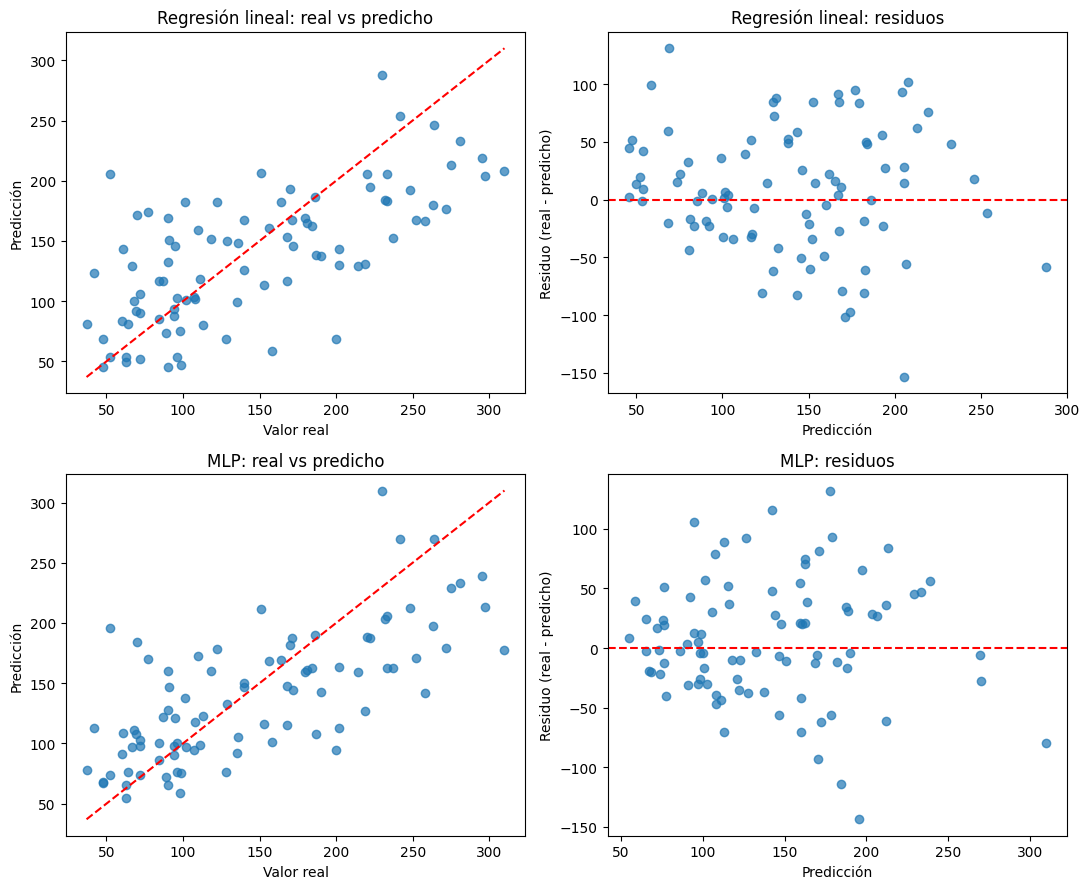

In [196]:
# Graficos
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for fila, nombre, pred in [(0, "Regresión lineal", y_pred_test_lin), (1, "MLP", y_pred_test_mlp)]:
    real = yd_test.values

    ax = axes[fila, 0]
    ax.scatter(real, pred, alpha=0.7)
    lim = [real.min(), real.max()]
    ax.plot(lim, lim, "r--")
    ax.set_xlabel("Valor real"); ax.set_ylabel("Predicción")
    ax.set_title(f"{nombre}: real vs predicho")

    ax = axes[fila, 1]
    ax.scatter(pred, real - pred, alpha=0.7)
    ax.axhline(0, color="r", linestyle="--")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Residuo (real - predicho)")
    ax.set_title(f"{nombre}: residuos")
plt.tight_layout()
plt.show()

In [197]:
for nombre, pred in [("Regresión lineal", y_pred_test_lin), ("MLP", y_pred_test_mlp)]:
    err = np.abs(yd_test.values - pred)
    idx = np.argsort(err)[-2:][::-1]
    grandes = Xd_test.iloc[idx].copy()
    grandes["real"] = yd_test.values[idx]
    grandes["predicho"] = pred[idx].round(1)
    grandes["error_abs"] = err[idx].round(1)
    print(nombre)
    print(grandes, "\n")

print("Rango del objetivo en entrenamiento:", yd_train.min(), "-", yd_train.max())

Regresión lineal
         age       sex       bmi        bp       s1        s2        s3  \
56 -0.041840 -0.044642  0.041218 -0.026328 -0.03184 -0.030437 -0.036038   
77 -0.096328 -0.044642 -0.036385 -0.074527 -0.03872 -0.027618  0.015505   

          s4        s5        s6   real  predicho  error_abs  
56  0.002943  0.033654 -0.017646   52.0     205.7      153.7  
77 -0.039493 -0.074093 -0.001078  200.0      69.0      131.0   

MLP
        age       sex       bmi        bp        s1        s2        s3  \
56 -0.04184 -0.044642  0.041218 -0.026328 -0.031840 -0.030437 -0.036038   
9  -0.07090 -0.044642  0.039062 -0.033213 -0.012577 -0.034508 -0.024993   

          s4        s5        s6   real  predicho  error_abs  
56  0.002943  0.033654 -0.017646   52.0     195.7      143.7  
9  -0.002592  0.067737 -0.013504  310.0     177.8      132.2   

Rango del objetivo en entrenamiento: 25.0 - 346.0


# Interpretación
1. El modelo que tuvo un mejor desempeño fue el Random Forest, que tuvo un error ligeramente menor que al resto de los modelos.
2. El MAE promedia todos los errores absolutos y los penalizas por igual, mientras que el RMSE penaliza a los errores muchos mas grandes. Un modelo con errores minimos favorecera a un RMSE ya que tipicamente son bajos, pero cambiaria si tuviera al menos un error catastrofico, cosa que no pasaria con MAE ya que no hace esta excepción para errores grandes.
3. Un R^2 negativo significaria que el modelo ni siquiera puede llegar a predecir mejor que la media de todos los datos.
4. Al aumentar la regularización aumento el sobreajuste del modelo. A primera vista pareceria que estaba estabilizando el error, pero llegado a cierto punto empezó a empeorarlo.
5. Podria significar que los modelos tienden a predecir cerca de la media por lo cual datos atipicos pueden sobreestimarse sobre datos regulares. Pero es extremadamente dificil poder afirmar si estos errores se dan por esta cuestión o por errores de cálculo o de medición.
6. No realmente, ya que una regresión lineal solo puede demostrar la interrelación de las características del dataset o una corelación estadistica entre estas.  